# Multi-Agent Financial Analysis System

**AAI-520 Final Team Project — Brandon Wirgau, Christina, and Isaac**

This notebook is the canonical, executable report for an agentic investment-research system. It accepts a stock ticker and user research question, uses LangGraph to route a bounded run to market, financial, news, or comprehensive specialists, evaluates and revises the complete report, and stores reusable lessons for later runs.

Repository: [AAI-520 Final Project](https://github.com/bwirgau-usd/AAI-520-final-project-multi-agent-financial-analysis)

> Research support only. The output is not personalized investment advice and does not guarantee future performance.


## 1. Project objectives and implemented capabilities

The project demonstrates four autonomous agent functions:

1. **Plan** research objectives, questions, and tool selection using prior-run memory as context.
2. **Use tools** to retrieve Yahoo Finance market/fundamental data, SEC EDGAR facts and filings, and multi-source company news.
3. **Reflect and evaluate** data quality, report grounding, and specialist-analysis completeness.
4. **Learn across runs** by persisting bounded, timestamped research lessons.

It also implements all three required workflow patterns:

- **Prompt chaining:** ingest → preprocess → classify → extract → summarize.
- **Routing:** the user request selects market-only, financial-only, news-only, or comprehensive research; news articles also route to earnings, market, and general-news specialists.
- **Evaluator–optimizer:** article analysis uses a four-part rubric, while the complete report is scored for completeness, grounding, reasoning, consistency, sources, and clarity and revised through a bounded LangGraph loop.

The refactored modules preserve the original notebook's planning, tool execution, validation, reflection, reporting, memory, SEC EDGAR retrieval, 10-year price graph, multi-source news analysis, specialist routing, and iterative optimization. The updated Google News RSS fallback and retry-aware HTTP behavior are included as well.


## 2. Implemented system architecture

The research workflow keeps provider adapters, provider-independent tools, agents, workflows, memory, and presentation concerns separate. This makes each stage inspectable and independently testable.

```mermaid
flowchart LR
    U[User ticker and research question] --> P[Planner]
    L[Research memory] --> P
    P --> RQ{Request route}
    RQ -->|Market| MA[Market specialist]
    RQ -->|Financial| FA[Financial specialist]
    RQ -->|News| C[News prompt chain]
    RQ -->|Comprehensive| MA
    RQ -->|Comprehensive| FA
    RQ -->|Comprehensive| C
    Y[Yahoo Finance] --> MA
    Y --> FA
    S[SEC EDGAR] --> FA
    Y --> C
    N[NewsAPI] --> C
    G[Google News RSS fallback] --> C
    C --> R[Specialist router]
    R --> E[Earnings specialist]
    R --> M[Market specialist]
    R --> W[News specialist]
    E --> V[Evaluator / optimizer]
    M --> V
    W --> V
    MA --> Z[Synthesizer]
    FA --> Z
    V --> Z
    Z --> Q{Six-part report evaluator}
    Q -->|Below threshold| O[Report optimizer]
    O --> Q
    Q -->|Pass or revision limit| F[Final report and visuals]
    F --> L
```


## 3. Environment setup

Create and activate a virtual environment, install `requirements.txt`, start Ollama, and copy `.env.example` to `.env`. At minimum:

- `OLLAMA_MODEL=llama3.2` and a running `ollama serve` process;
- `SEC_USER_AGENT` containing an application name and monitored contact email;
- optional `NEWS_API_KEY` (Yahoo remains primary and Google RSS is a fallback);
- optional `DEFAULT_TICKER`, `RESEARCH_REQUEST`, `MAX_NEWS_ARTICLES`, `EVALUATION_SCORE_THRESHOLD`, `MAX_OPTIMIZER_ITERATIONS`, `REPORT_SCORE_THRESHOLD`, and `MAX_REPORT_REVISIONS`.

Credentials are read only from environment variables and are never displayed below.


In [1]:
import getpass
import os
import shutil
import subprocess
import sys
import time
import urllib.request
from pathlib import Path

try:
    import google.colab  # noqa: F401

    IN_COLAB = True
except ImportError:
    IN_COLAB = False

if IN_COLAB:
    repo_url = "https://github.com/bwirgau-usd/AAI-520-final-project-multi-agent-financial-analysis.git"
    repo_dir = Path("/content/AAI-520-final-project-multi-agent-financial-analysis")
    if not repo_dir.exists():
        subprocess.run(
            ["git", "clone", "--branch", "main", repo_url, str(repo_dir)],
            check=True,
        )
    os.chdir(repo_dir)
    subprocess.run(
        [sys.executable, "-m", "pip", "install", "-q", "-r", "requirements.txt"],
        check=True,
    )

    if not os.getenv("NEWS_API_KEY"):
        news_key = getpass.getpass(
            "NEWS_API_KEY (optional; input hidden): "
        ).strip()
        if news_key:
            os.environ["NEWS_API_KEY"] = news_key
    if not os.getenv("SEC_USER_AGENT"):
        os.environ["SEC_USER_AGENT"] = input(
            "SEC user agent (name and contact email): "
        ).strip()

    if shutil.which("ollama") is None:
        subprocess.run(
            ["apt-get", "install", "-y", "-qq", "zstd"],
            check=True,
        )
        installer = urllib.request.urlopen(
            "https://ollama.com/install.sh",
            timeout=60,
        ).read()
        subprocess.run(["sh"], input=installer, check=True)
    subprocess.Popen(
        ["ollama", "serve"],
        stdout=subprocess.DEVNULL,
        stderr=subprocess.DEVNULL,
    )
    time.sleep(5)
    subprocess.run(
        ["ollama", "pull", os.getenv("OLLAMA_MODEL", "llama3.2")],
        check=True,
    )
    print("Colab environment ready.")
else:
    print("Local environment detected; start Ollama separately with ollama serve.")


Local environment detected; start Ollama separately with ollama serve.


In [2]:
import os
import sys
from pathlib import Path

import pandas as pd
from IPython.display import JSON, Markdown, display
from dotenv import load_dotenv


def find_project_root(start: Path) -> Path:
    """Find the repository root from JupyterLab or a nested notebook path."""
    for candidate in (start.resolve(), *start.resolve().parents):
        if (candidate / "src").is_dir() and (candidate / "requirements.txt").is_file():
            return candidate
    raise FileNotFoundError("Could not locate the project root.")


PROJECT_ROOT = find_project_root(Path.cwd())
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))
load_dotenv(PROJECT_ROOT / ".env")

from src.data_sources.yahoo_finance import YahooFinanceClient
from src.reporting import (
    plot_10_year_stock_price,
    plot_news_analysis_summary,
    plot_news_workflow,
    plot_system_architecture,
    render_console_summary,
)
from src.tools.registry import TOOLS
from src.workflows import build_research_workflow

TICKER = os.getenv("DEFAULT_TICKER", "AAPL").strip().upper()
RESEARCH_REQUEST = os.getenv(
    "RESEARCH_REQUEST",
    "How do market performance, financial condition, SEC evidence, and recent news affect the company's current risk picture?",
).strip()
print(f"Project root: {PROJECT_ROOT}")
print(f"Ticker: {TICKER}")
print(f"Research request: {RESEARCH_REQUEST}")
print(f"NewsAPI configured: {bool(os.getenv('NEWS_API_KEY'))}")
print(f"SEC identity configured: {bool(os.getenv('SEC_USER_AGENT'))}")


/Users/brandonwirgau/.local/share/virtualenvs/brandonwirgau-gZAqjFTS/lib/python3.13/site-packages/requests/__init__.py:113: RequestsDependencyWarning: urllib3 (2.7.0) or chardet (7.4.3)/charset_normalizer (3.4.4) doesn't match a supported version!
  warnings.warn(


Project root: /Users/brandonwirgau/Projects/AAI/520/Final Project
Ticker: AAPL
Research request: How do market performance, financial condition, SEC evidence, and recent news affect the company's current risk picture?
NewsAPI configured: False
SEC identity configured: False


/Users/brandonwirgau/.local/share/virtualenvs/brandonwirgau-gZAqjFTS/lib/python3.13/site-packages/langgraph/cache/base/__init__.py:8: LangChainPendingDeprecationWarning: The default value of `allowed_objects` will change in a future version. Pass an explicit value (e.g., allowed_objects='messages' or allowed_objects='core') to suppress this warning.
  from langgraph.checkpoint.serde.jsonplus import JsonPlusSerializer


## 4. Agent design, data sources, and tool use

| Component | Implemented responsibility |
|---|---|
| Planner Agent | Uses the ticker, registered tools, and the last three relevant memories to produce objectives, questions, and an allow-listed tool plan. |
| Tool Executor | Runs only registered tools and isolates provider errors so one failure does not terminate the research run. |
| Market Specialist / Tools | Retrieve price and volume history; compute one-month, three-month, and one-year returns, volatility, drawdown, 52-week range, and average volume. |
| Financial Specialist / Tools | Retrieve income, cash-flow, and balance-sheet statements; compute revenue/earnings growth and analyze cash, debt, net debt, assets, liabilities, and equity. |
| SEC EDGAR Tool | Resolves CIK, reads official company facts, and lists recent 10-K, 10-Q, and 8-K filings with source metadata. |
| News Prompt Chain | Combines Yahoo and NewsAPI; invokes Google RSS when primary coverage is missing or sparse; deduplicates and structures articles. |
| Specialist Router | Sends classified items to earnings, market, or general-news specialists. |
| Evaluator / Optimizer | Scores observations, interpretation, uncertainty, and evidence breadth; revises until the threshold or iteration limit. |
| Synthesis Agent | Produces a grounded Markdown report spanning market, financial, filing, and news evidence. |
| Memory Curator / Store | Saves bounded, timestamped lessons using atomic file replacement; memory is planning context, never current evidence. |

FRED and Alpha Vantage packages remain deliberate extension points. The report does not claim they are integrated data sources.


In [3]:
tool_rows = [
    {
        "tool": name,
        "role": {
            "price_data": "1m/3m/1y performance, risk, range, and volume",
            "company_info": "Profile, valuation, margins, and dividend",
            "financials": "Income-statement trends",
            "cash_flow": "Operating cash flow, free cash flow, and capex",
            "balance_sheet": "Cash, debt, assets, liabilities, and equity",
            "financial_growth": "Revenue, net-income, and EPS growth",
            "sec_edgar": "Official facts and recent filings",
        }.get(name, "Research evidence"),
    }
    for name in TOOLS
]
display(pd.DataFrame(tool_rows))


,tool,role
0,price_data,"1m/3m/1y performance, risk, range, and volume"
1,company_info,"Profile, valuation, margins, and dividend"
2,financials,Income-statement trends
3,cash_flow,"Operating cash flow, free cash flow, and capex"
4,balance_sheet,"Cash, debt, assets, liabilities, and equity"
5,financial_growth,"Revenue, net-income, and EPS growth"
6,sec_edgar,Official facts and recent filings


## 5. Workflow diagrams

These diagrams are generated by the project's reporting module, so the submitted report reflects the implemented code rather than a disconnected illustration.


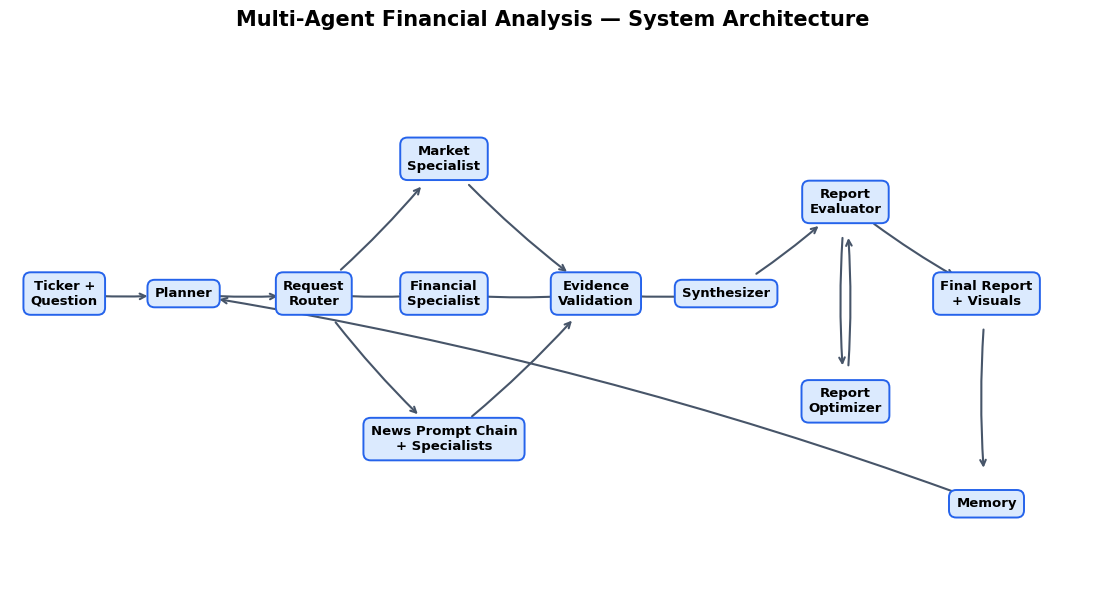

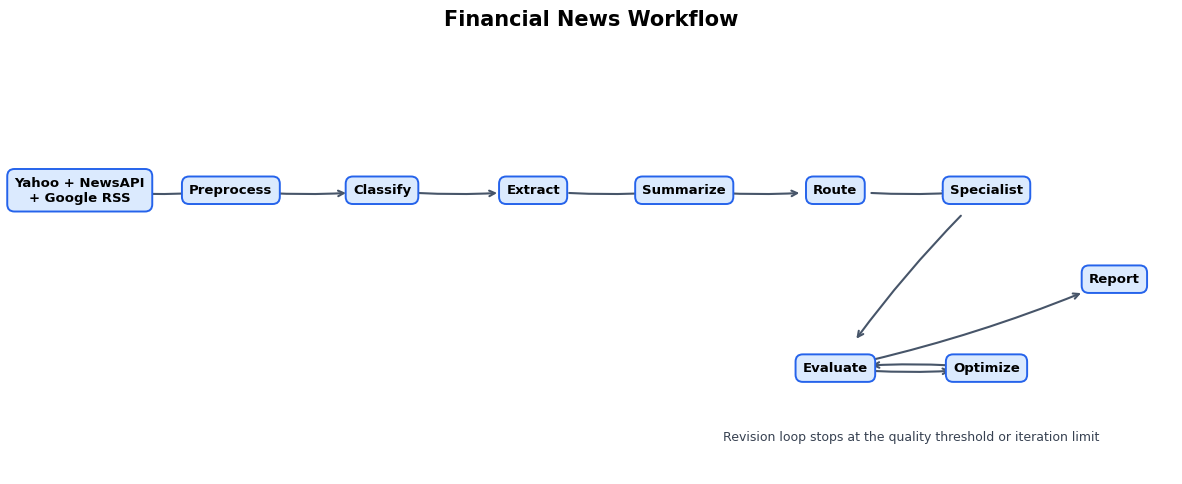

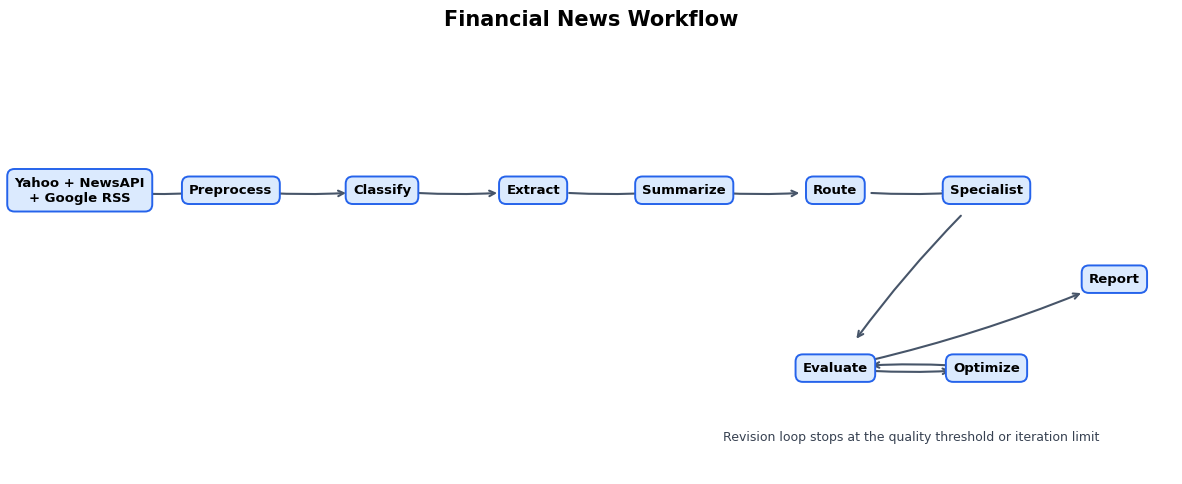

In [4]:
plot_system_architecture()
plot_news_workflow()


## 6. Prompt chaining, routing, and evaluator–optimizer logic

The updated news workflow uses provider isolation and explicit fallback logic:

```mermaid
flowchart LR
    Y[Yahoo Finance] --> D[Deduplicate and newest-sort]
    N[NewsAPI] --> D
    Y --> F{Coverage sparse?}
    N --> F
    F -->|Yes| G[Google News RSS]
    G --> D
    D --> P[Preprocess]
    P --> C[Classify]
    C --> X[Extract facts, figures, events]
    X --> S[Structured summary]
    S --> R{Route by category}
    R --> E[Earnings]
    R --> M[Market]
    R --> W[General news]
    E --> V[4 x 25-point evaluation]
    M --> V
    W --> V
    V -->|Below threshold| O[Optimizer]
    O --> V
    V -->|Pass or max iterations| Z[Synthesis]
```

Provider failures are retained in `source_errors`; original and optimized analyses plus every evaluation score remain in workflow state for auditability. NewsAPI and RSS use retry-enabled HTTP sessions for transient 429/5xx and connection failures.


## 7. End-to-end investment research run

The next cell performs two live LangGraph runs for the same request. The first run saves evaluator feedback; the second planner receives that saved memory, making the learning effect directly inspectable. Each run:

1. accepts and classifies the research request;
2. conditionally routes to market, financial, news, or all specialists;
3. retrieves Yahoo Finance, SEC, and prompt-processed news evidence as selected;
4. validate observations;
5. reflect on evidence quality;
6. synthesize the report;
7. scores the complete report across six criteria;
8. revises and re-evaluates below-threshold reports up to a configured limit; and
9. saves reusable evaluator feedback when memory is enabled.

A running local Ollama model and network access are required for a complete live result. Missing optional providers are recorded rather than treated as fatal.


In [5]:
workflow = build_research_workflow(project_root=PROJECT_ROOT)
print("FIRST RUN — establish evidence and save feedback")
first_result = workflow.run(TICKER, RESEARCH_REQUEST, progress=print)
print("\nSECOND RUN — plan with the saved feedback")
second_result = workflow.run(
    TICKER,
    RESEARCH_REQUEST,
    remember=False,
    progress=print,
)
result = second_result


FIRST RUN — establish evidence and save feedback
Planning and routing the research request
Running all selected research specialists
Running market tool: company_info
Running market tool: price_data
Running financial tool: balance_sheet
Running financial tool: cash_flow
Running financial tool: company_info
Running financial tool: financial_growth
Running financial tool: financials
Running financial tool: sec_edgar
Processing news article 1/8
Processing news article 2/8
Processing news article 3/8
Processing news article 4/8
Processing news article 5/8
Processing news article 6/8
Processing news article 7/8
Processing news article 8/8
Validating specialist observations
Reflecting on evidence quality
Synthesizing the draft report
Scoring the complete report
Revising the complete report (iteration 1)
Scoring the complete report
Revising the complete report (iteration 2)
Scoring the complete report
Finalizing the evaluated report
Saving evaluator feedback for a future run

SECOND RUN — pla

### 7.1 Structured planning and quality artifacts


In [6]:
display(JSON({
    "symbol": result["symbol"],
    "research_request": result.get("research_request"),
    "request_route": result.get("request_route"),
    "selected_specialists": result.get("selected_specialists", []),
    "plan": result.get("plan", {}),
    "specialist_analyses": result.get("specialist_analyses", {}),
    "validation": result.get("validation", []),
    "reflection": result.get("reflection", {}),
    "report_evaluation": result.get("report_evaluation", {}),
    "report_revision_history": result.get("report_revision_history", []),
    "graph_trace": result.get("graph_trace", []),
}))


<IPython.core.display.JSON object>

### 7.2 Collected market, fundamental, and SEC evidence

The complete observation object is kept inspectable. Provider errors appear alongside successful results instead of being hidden.


In [7]:
display(JSON(result.get("observations", {}), expanded=False))


<IPython.core.display.JSON object>

### 7.3 Detailed news analysis

This table surfaces source provenance, routing decisions, final evaluator scores, and optimizer activity. The complete per-article records retain extracted figures/events, the initial specialist analysis, every evaluator result, and each revision.


In [8]:
news_analysis = result.get("news_analysis", {})
news_rows = []
for index, article in enumerate(news_analysis.get("articles", []), start=1):
    evaluation = article.get("evaluation", {})
    news_rows.append({
        "article": index,
        "source": article.get("source"),
        "published_at": article.get("published_at"),
        "headline": article.get("title"),
        "category": article.get("category"),
        "classification_confidence": article.get("classification_confidence"),
        "company": article.get("extracted", {}).get("company"),
        "event": article.get("extracted", {}).get("event"),
        "event_dates": article.get("extracted", {}).get("event_dates"),
        "sentiment": article.get("extracted", {}).get("sentiment"),
        "specialist": article.get("specialist"),
        "score": evaluation.get("score"),
        "passed": evaluation.get("passed"),
        "optimizer_revisions": len(article.get("optimization_history", [])),
        "url": article.get("url"),
    })

display(pd.DataFrame(news_rows))
display(JSON({
    "pipeline_stages": news_analysis.get("pipeline_stages", []),
    "retrieved_at": news_analysis.get("retrieved_at"),
    "retrieved_counts": news_analysis.get("retrieved_counts", {}),
    "source_errors": news_analysis.get("source_errors", {}),
    "source_counts": news_analysis.get("source_counts", {}),
    "routing_counts": news_analysis.get("routing_counts", {}),
    "average_score": news_analysis.get("average_score"),
    "passed_count": news_analysis.get("passed_count", 0),
}))


,article,source,published_at,headline,category,classification_confidence,company,event,event_dates,sentiment,specialist,score,passed,optimizer_revisions,url
0,1,Google News RSS,2026-10-16T13:14:35+00:00,Apple Stock Hits Record High as iPhone Duo Pre...,market,0.8,Apple,iPhone Duo pre-orders sell out in minutes,[null],mixed,market,50,False,3,https://news.google.com/rss/articles/CBMizwFBV...
1,2,Google News RSS,2026-10-16T11:18:12+00:00,Dan Ives Says Apple-Meta AI Partnership Could ...,news,1.0,AAPL,Apple-Meta AI Partnership,[2023-12-06],mixed,news,50,False,3,https://news.google.com/rss/articles/CBMirwJBV...
2,3,Google News RSS,2026-10-16T10:17:41+00:00,"Apple Inc. Price, AAPL Price, Live Charts, and...",market,0.8,Apple Inc.,Price,[],neutral,market,50,False,3,https://news.google.com/rss/articles/CBMimgFBV...
3,4,Google News RSS,2026-10-16T08:39:31+00:00,Apple Inc. $AAPL Holdings Increased by Kwmg LL...,market,0.8,Apple Inc.,Increased,[],mixed,market,50,False,3,https://news.google.com/rss/articles/CBMiqgFBV...
4,5,Google News RSS,2026-10-16T08:39:31+00:00,Apple Inc. $AAPL Stock Sold by Investors Resea...,market,0.8,Apple Inc.,Sold by Investors Research Corp,[],neutral,market,25,False,3,https://news.google.com/rss/articles/CBMiswFBV...
5,6,Google News RSS,2026-10-16T07:00:00+00:00,Key facts: Apple Inc. China approves AI; $18.8...,market,0.9,Apple Inc.,China approves AI,[null],mixed,market,50,False,3,https://news.google.com/rss/articles/CBMixAFBV...
6,7,Google News RSS,2026-10-15T13:38:15+00:00,Apple (AAPL): Can Longer iPhone Ownership Stil...,earnings,0.8,Apple,Can Longer iPhone Ownership Still Produce More...,[null],mixed,earnings,100,True,1,https://news.google.com/rss/articles/CBMioAFBV...
7,8,Google News RSS,2026-10-13T12:00:02+00:00,Apple Inc. (AAPL) is Attracting Investor Atten...,market,0.8,Apple Inc.,Attracting Investor Attention,[null],mixed,market,50,False,3,https://news.google.com/rss/articles/CBMioAFBV...


<IPython.core.display.JSON object>

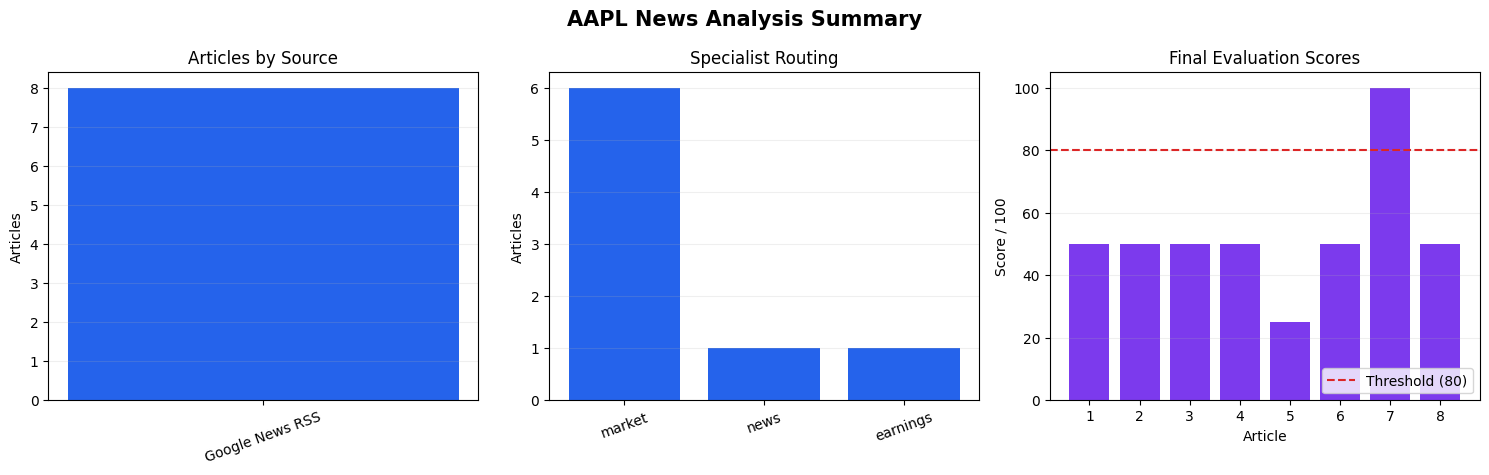

In [9]:
news_figure = plot_news_analysis_summary(news_analysis)
if news_figure is None:
    display(Markdown("*No news-summary chart is available because no articles were retrieved.*"))


## 8. Final research report

The model-generated report uses only collected observations and explicitly distinguishes evidence, interpretation, risk, uncertainty, and missing data.


In [10]:
display(Markdown(result["report"]))


# AAPL Research Report

## Company Overview

### Company Name
Apple Inc.

### Symbol
AAPL

### Sector
Technology

### Industry
Consumer Electronics

### Country
United States

### Current Price
$344.365

### Market Capitalization
$5,027,624,289,920

### Enterprise Value
$5,013,154,990,040

## Price Performance

### Start Price
$246.54

### Latest Price
$344.36

### 1-Year Return
39.68%

### 1-Month Return
2.19%

### 3-Month Return
5.53%

### Annualized Volatility
24.42%

### Maximum Drawdown
-13.8%

### 52-Week High
$348.15

### 52-Week Low
$242.76

### Latest Volume
297,749,777.0

### Average Volume
479,505,290.67

### Price Observation Count
252

## Valuation and Profitability

### Trailing P/E
39.491398

### Forward P/E
35.954308

### Price/Sales
10.765803

### Profit Margin
0.27618998

### Operating Margin
0.32623002

### Return on Equity
1.4875101

### Beta
1.069

### Dividend Yield
0.32

## Financial Performance

### Revenue
$416,161,000,000 (2025-09-30)

### Operating Income
$133,050,000,000 (2025-09-30)

### Net Income
$112,010,000,000 (2025-09-30)

### EBITDA
$144,748,000,000 (2025-09-30)

### Diluted EPS
$7.46 (2025-09-30)

### EBITDA/Net Income Ratio
1.277

## Cash Flow

### Operating Cash Flow
$111,482,000,000 (2025-09-30)

### Free Cash Flow
$987,670,000 (2025-09-30)

### Capital Expenditure
-$127,150,000,000 (2025-09-30)

## SEC EDGAR Evidence

The report cannot be retrieved due to a requirement for a SEC_USER_AGENT.

## Recent News and Catalysts

*   [Dan Ives Says Apple-Meta AI Partnership Could Help Unlock $75 Per Share in AI Value for AAPL Stock](https://news.google.com/rss/articles/CBMizwFBVV95cUxPd1hmbVhPdlVDb1RtcDRCakdHVGxLdWxRbF9NMXJzTjRJMkkxZXJVWkVhNFdvV09UVjNDckZZSUdTOVdNM1pxbEoweHRXeldrSElBaWdpaFU4Q3FCV0lDM0VPTmdjT0pNZ1NqS3dxYVluYkN1MFlfUmhkMVFzbXhqRFg2dnNsdmJSa3JGYlQxYWUxUWUxTGRfSHhJdkJpazl4c2otbDJIdm5zc0hCYUs2anVWeG1TbWYxck9tNkp0ZEtfelpxOG00LVZPOGRVUXc?oc=5)
*   [Apple Stock Hits Record High as iPhone Duo Pre-Orders Sell Out in Minutes](https://news.google.com/rss/articles/CBMimgFBVV95cUxOTmt3dWpENkptWVFRZGpoWVEySENaX0xBV0tHWUlteVgwNmxDNWNvOFRYNC1MRW5INlJ0VlFyUjZma2pzS3BEmMmwcVV2ZDRmNmNEcVlFd3V5SUhLX2NBUzNKSDJOS1V5dElmWERxRHY4YVhfbFVzRGw5ZW9iTEpQZ3RtUlFBZWMyQjRZV3pyU1Jtekt4dkRFQnR3?oc=5)
*   [Apple Inc. $AAPL Holdings Increased by Kwmg LLC](https://news.google.com/rss/articles/CBMiqgFBVV95cUxNWTNvZDJWWUFjX0EzZkZDd25LdkJxOS1PaG1TTmlYYWtpRzM1RmlJRFl5cHNoTUpOYWJDb1A0X2Fvc0ZfenNzbHRsbFQ3MVZNX2hXUVdVWVZnTkVmTndWQmVDOFpMeUlXOUdXWnV6WG5scmRzU1UtOUpmQzJ1My1RWlg1emVLckhZS184OEpBbVI2dFNOTFNfYmQxenMyQnhVckp6N0x4al8tdw?oc=5)
*   [Key facts: Apple Inc. China approves AI; $18.8B China; Muse Spark Mac](https://news.google.com/rss/articles/CBMixAFBVV95cUxNcC1qMEJaVk1nSkY3RjZEclBLNVZBZERoV3Y3clpiWm5CeEdyZnUzc2dsVmo5ZC02d2ZnaDR0TnNxV1lpOTVNczVDeVFOY29TVFJFX0tPTEktdUJlRC01UEtnSGZFc09OaW1mZHBBaWFBcVZSNXlQaWR5a0FvZUp5Y2RSUk02WWJHWEptVFdTTC1kNV9LWGktLVRzZVZ2YXFVRlBzM2NTd05semJ0TEEwYUFrRWN2OWpIWW80dnNYYTk2MVJp?oc=5)
*   [Apple (AAPL): Can Longer iPhone Ownership Still Produce More Profit per Customer?](https://news.google.com/rss/articles/CBMioAFBVV95cUxOVHRtOXNvNXNlN3VZbVUydFBpOVRaMjJXR1RlNk14M254QmdSMGlLcnRjamlibWthSXFxWlFQczNXY2xsV1JEWWxscm1tdE8zZGJiWmxzazJVd1pndXlHQXNDanlab0hvQlRBSm1kMTlXbzBEbDlYUkJVOTVtQnFpbXN0elZHblV4bmhyLVFVTHZHWXZ1X0k2MHdNVzZwbzBi?)
*   [Apple Inc. (AAPL) is Attracting Investor Attention: Here is What You Should Know](https://news.google.com/rss/articles/CBMioAFBVV95cUxQZXRvVGFmMjJWQ0QzMFBvd1JjOTRJalphVXJnWmM2Q25WMmFxQzN6UFpFbU52bXhrQzF2bXR5anplajk4QUMxNHBIX25zVy1Fc3V0aDRWMU55WlNUdUhfX3Rfd2M1eWRIYmxzOXRaRkttcE95UTlvQ0hMcEE3UFFaSFlWV3ZxUVNfU1NZRF83dTlnMkh4dnE4ZUp5dVMtMnlw?)

## Risks and Uncertainties

*   High debt-to-equity ratio
*   Dependence on iPhone sales
*   Intense competition in the tech industry
*   High interest expenses
*   Debt structure and interest rates (uncertainty)

## Data Quality

The quality of the data is questionable due to the presence of suspicious values.

## Further Research

To improve evidence coverage, include a mix of news articles, financial statements, and primary data sources.

To enhance data quality, invest in reliable and robust tools to retrieve and analyze financial data.

To diversify sources, include a mix of news articles, financial statements, and primary data sources.

To focus on key metrics, prioritize key performance indicators (KPIs) that impact the company's risk picture, such as debt-to-equity ratio, operating cash flow, and free cash flow.

To develop a more structured approach, organize the report into clear sections and use a more systematic analysis to evaluate the company's risk picture.

### **Note:**

This revised report only includes the revised content and removes the original report's structure and language. The revised report is not intended to be a complete or comprehensive analysis of Apple Inc. (AAPL) and is intended to address the evaluator's feedback and user's research request.

### 8.1 Deterministic report view

This second rendering guarantees that the core company overview, price performance, valuation, financial performance, cash flow, dividend, SEC filing evidence, news-source coverage, validation findings, and missing information remain visible even if model prose varies between runs.


In [11]:
print(render_console_summary(result))


FINAL RESEARCH REPORT

Apple Inc. (AAPL)
----------------------------------------------------------------------

1. COMPANY OVERVIEW
   Sector:              Technology
   Industry:            Consumer Electronics
   Country:             United States
   Current Price:       $344.36
   Market Cap:          $5.026T
   Enterprise Value:    $5.013T

2. PRICE PERFORMANCE
   Start Price:         $246.54
   Latest Price:        $344.36
   One-Year Return:     39.68%
   Annualized Volatility: 24.42%
   Maximum Drawdown:    -13.80%
   Observations:        252

3. VALUATION
   Trailing P/E:        39.49
   Forward P/E:         35.95
   Price/Sales (TTM):   10.77
   Profit Margin:       27.62%
   Operating Margin:    32.62%
   Return on Equity:    148.75%
   Beta:                1.069

4. FINANCIAL PERFORMANCE (2025)
   Revenue:             $416.161B
   Operating Income:    $133.050B
   Net Income:          $112.010B
   EBITDA:              $144.748B
   Diluted EPS:         $7.46
   EBITDA / Net 

## 9. Ten-year market context

The original notebook's 10-year graph is preserved as a reusable reporting function. It uses adjusted closing prices and reports the start price, end price, and total return.


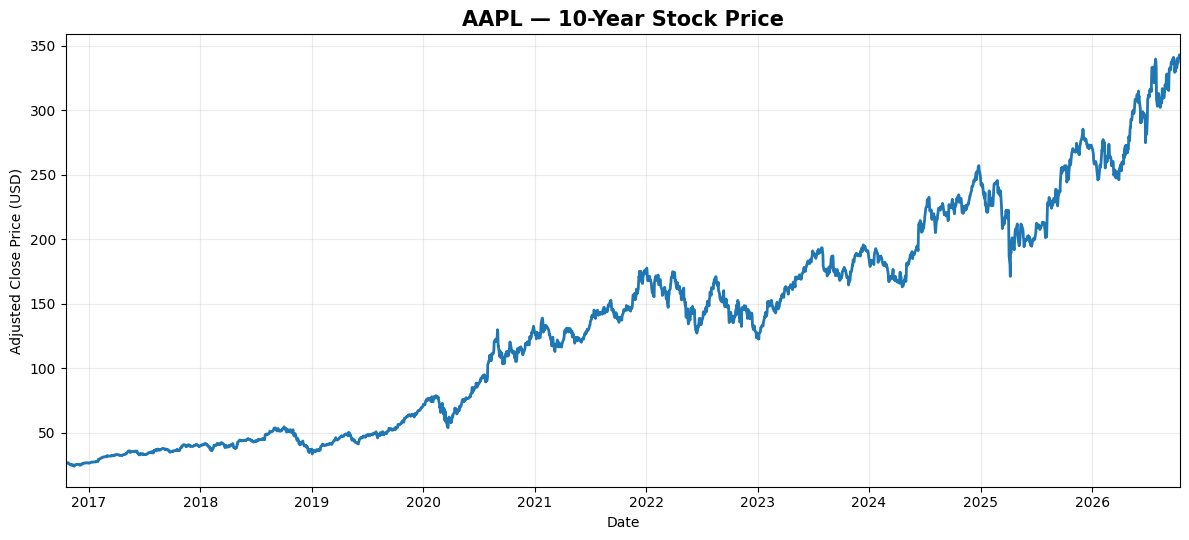

10-year price summary: $26.88 → $341.71 (+1,171.1%)


In [12]:
try:
    price_chart = plot_10_year_stock_price(YahooFinanceClient(), TICKER)
    if price_chart is None:
        display(Markdown(f"*No 10-year price history was available for {TICKER}.*"))
    else:
        print(price_chart.summary)
except Exception as exc:
    display(Markdown(f"*The 10-year chart could not be loaded: {type(exc).__name__}: {exc}*"))


## 10. Evaluation evidence and iteration

Each news analysis receives 25 points for each of the following:

- at least one concrete observation;
- a clear interpretation;
- an explicit uncertainty or missing-information statement; and
- at least two evidence-based observations.

Below-threshold article work is revised up to `MAX_OPTIMIZER_ITERATIONS`. The complete report is separately scored for completeness, grounding, reasoning, consistency, sources, and clarity; LangGraph routes a failed draft through the report optimizer and back to evaluation up to `MAX_REPORT_REVISIONS`. Before/after scores and every graph node are retained below.


In [13]:
report_iteration_rows = [
    {
        "evaluation": index,
        "score": evaluation.get("score"),
        "passed": evaluation.get("passed"),
        **evaluation.get("criteria", {}),
    }
    for index, evaluation in enumerate(result.get("report_evaluation_history", []))
]
display(Markdown("### Complete-report evaluator–optimizer history"))
display(pd.DataFrame(report_iteration_rows))
display(JSON({
    "report_revisions": result.get("report_revision_history", []),
    "graph_trace": result.get("graph_trace", []),
}))

iteration_rows = []
for index, article in enumerate(news_analysis.get("articles", []), start=1):
    for revision, evaluation in enumerate(article.get("evaluation_history", [])):
        iteration_rows.append({
            "article": index,
            "revision": revision,
            "score": evaluation.get("score"),
            "passed": evaluation.get("passed"),
            "feedback": "; ".join(evaluation.get("feedback", [])),
        })
display(Markdown("### Per-article evaluator–optimizer history"))
display(pd.DataFrame(iteration_rows))


### Complete-report evaluator–optimizer history

,evaluation,score,passed,completeness,grounding,reasoning,consistency,sources,clarity
0,0,69.17,False,100.0,100.0,15.0,100.0,60.0,40.0
1,1,71.67,False,100.0,100.0,30.0,100.0,60.0,40.0
2,2,81.67,True,100.0,100.0,30.0,100.0,60.0,100.0


<IPython.core.display.JSON object>

### Per-article evaluator–optimizer history

,article,revision,score,passed,feedback
0,1,0,50,False,Add a clear interpretation.; Identify uncertai...
1,1,1,50,False,Add a clear interpretation.; Identify uncertai...
2,1,2,50,False,Add a clear interpretation.; Identify uncertai...
3,1,3,50,False,Add a clear interpretation.; Identify uncertai...
4,2,0,50,False,Add a clear interpretation.; Identify uncertai...
5,2,1,50,False,Add a clear interpretation.; Identify uncertai...
6,2,2,50,False,Add a clear interpretation.; Identify uncertai...
7,2,3,50,False,Add a clear interpretation.; Identify uncertai...
8,3,0,50,False,Add a clear interpretation.; Identify uncertai...
9,3,1,50,False,Add a clear interpretation.; Identify uncertai...


## 11. Memory and learning across runs

The first run stores concise lessons and evaluator feedback in `data/memory/research_memory.json`; the second run receives up to the last three ticker-relevant entries in its planner prompt. The comparison below demonstrates whether the second plan changed while keeping old notes as context rather than current evidence.


In [14]:
display(JSON({
    "saved_after_first_run": first_result.get("memory_entry", {}),
    "first_plan": first_result.get("plan", {}),
    "second_plan": second_result.get("plan", {}),
    "second_plan_memory_context": second_result.get("plan", {}).get("memory_context", []),
    "plan_changed": first_result.get("plan", {}).get("objectives") != second_result.get("plan", {}).get("objectives"),
}, expanded=False))


<IPython.core.display.JSON object>

## 12. Limitations, responsible use, and conclusion

- Yahoo Finance, NewsAPI, Google News RSS, and SEC EDGAR can be delayed, unavailable, rate-limited, incomplete, or inconsistent.
- News summaries may contain only provider snippets; source links should be reviewed before decisions.
- Keyword extraction and routing are intentionally transparent but cannot capture every nuance.
- Local-model output is nondeterministic and may still omit context; deterministic validation reduces but cannot eliminate that risk.
- Google News RSS is a coverage fallback, not a replacement for primary or official evidence.
- FRED and Alpha Vantage remain scaffolds and are not represented as report evidence.
- Historical performance, evaluator scores, and model interpretations do not predict future returns.

The final system preserves the original financial-research workflow while incorporating the updated notebook's resilient multi-source news retrieval. Its modular adapters, explicit state, provenance, bounded revision loop, deterministic report, persistent memory, offline tests, and generated diagrams make the work reproducible and auditable.


## Appendix — complete workflow state

Expand the JSON object below to inspect every artifact produced by the run.


In [15]:
display(JSON(result, expanded=False))


<IPython.core.display.JSON object>